## Imports and Settings


In [1]:
import datetime
import copy
import random
import math
import time
import numpy as np
import matplotlib.pyplot as plt
from decimal import Decimal, getcontext
from shapely import affinity
from shapely.geometry import Polygon
from shapely.ops import unary_union
from matplotlib.patches import Rectangle
from matplotlib.animation import FuncAnimation
import matplotlib.patches as mpatches

getcontext().prec = 25
scale_factor = Decimal("1e15")


## ChristmasTree Class

Represents a single Christmas tree with a fixed size that can be rotated.


In [2]:
class ChristmasTree:
    """Represents a single, rotatable Christmas tree of a fixed size."""

    def __init__(self, center_x="0", center_y="0", angle="0"):
        """Initializes the Christmas tree with a specific position and rotation."""
        self.center_x = Decimal(center_x)
        self.center_y = Decimal(center_y)
        self.angle = Decimal(angle)

        trunk_w = Decimal("0.15")
        trunk_h = Decimal("0.2")
        base_w = Decimal("0.7")
        mid_w = Decimal("0.4")
        top_w = Decimal("0.25")
        tip_y = Decimal("0.8")
        tier_1_y = Decimal("0.5")
        tier_2_y = Decimal("0.25")
        base_y = Decimal("0.0")
        trunk_bottom_y = -trunk_h

        initial_polygon = Polygon(
            [
                # Start at Tip
                (Decimal("0.0") * scale_factor, tip_y * scale_factor),
                # Right side - Top Tier
                (top_w / Decimal("2") * scale_factor, tier_1_y * scale_factor),
                (top_w / Decimal("4") * scale_factor, tier_1_y * scale_factor),
                # Right side - Middle Tier
                (mid_w / Decimal("2") * scale_factor, tier_2_y * scale_factor),
                (mid_w / Decimal("4") * scale_factor, tier_2_y * scale_factor),
                # Right side - Bottom Tier
                (base_w / Decimal("2") * scale_factor, base_y * scale_factor),
                # Right Trunk
                (trunk_w / Decimal("2") * scale_factor, base_y * scale_factor),
                (trunk_w / Decimal("2") * scale_factor, trunk_bottom_y * scale_factor),
                # Left Trunk
                (-(trunk_w / Decimal("2")) * scale_factor, trunk_bottom_y * scale_factor),
                (-(trunk_w / Decimal("2")) * scale_factor, base_y * scale_factor),
                # Left side - Bottom Tier
                (-(base_w / Decimal("2")) * scale_factor, base_y * scale_factor),
                # Left side - Middle Tier
                (-(mid_w / Decimal("4")) * scale_factor, tier_2_y * scale_factor),
                (-(mid_w / Decimal("2")) * scale_factor, tier_2_y * scale_factor),
                # Left side - Top Tier
                (-(top_w / Decimal("4")) * scale_factor, tier_1_y * scale_factor),
                (-(top_w / Decimal("2")) * scale_factor, tier_1_y * scale_factor),
            ]
        )
        rotated = affinity.rotate(initial_polygon, float(self.angle), origin=(0, 0))
        self.polygon = affinity.translate(
            rotated, xoff=float(self.center_x * scale_factor), yoff=float(self.center_y * scale_factor)
        )

    def get_params(self):
        return self.center_x, self.center_y, self.angle

    def set_params(self, center_x, center_y, angle):
        self.__init__(str(center_x), str(center_y), str(angle))

    def clone(self):
        """Create a deep copy of the tree."""
        return ChristmasTree(str(self.center_x), str(self.center_y), str(self.angle))


## Abstract Problem Class

Interface for an optimization problem. SA algorithm works with any Problem without knowing the details of a specific task.


## Example: How to Easily Create a New Task

Let's define abstract problem for SA

In [3]:
from abc import ABC, abstractmethod

class Problem(ABC):
    """
    Abstract class for an optimization problem.
    SA algorithm works with any Problem without knowing the details of a specific task.
    """
    
    @abstractmethod
    def get_initial_state(self):
        """Returns the initial state of the problem."""
        pass
    
    @abstractmethod
    def perturb(self, state):
        """
        Modifies the state of the problem.
        Returns (new_state, old_state_for_rollback).
        """
        pass
    
    @abstractmethod
    def evaluate(self, state):
        """
        Calculates the value of the function for the state.
        Lower = better (minimization).
        """
        pass
    
    @abstractmethod
    def is_valid(self, state):
        """Checks if the state is valid."""
        pass
    
    @abstractmethod
    def clone_state(self, state):
        """Creates a copy of the state."""
        pass

Simply inherit from `Problem` and implement the methods. Then use the same universal SA algorithm!

```
class MyNewProblem(Problem):
    def get_initial_state(self):
        # Return initial state
        pass
    
    def perturb(self, state):
        # Modify state
        # Return (new_state, rollback_data)
        pass
    
    def evaluate(self, state):
        # Calculate value (lower = better)
        pass
    
    def is_valid(self, state):
        # Check validity
        pass
    
    def clone_state(self, state):
        # Clone state
        pass

# Then use the same SA:
# my_problem = MyNewProblem(...)
# sa = SimulatedAnnealing(problem=my_problem, ...)
# best_value, best_state = sa.solve()
```

In [4]:
class SingleBlockProblem(Problem):
    """
    Base class for a single grid block problem.
    Can be used to build more complex problems (e.g., two-block).
    State is a dictionary with pair and grid parameters:
    {
        'pair': [tree0, tree1],  # Pair of trees (unit cell)
        'a': Decimal,            # Grid step in X
        'b': Decimal             # Grid step in Y
    }
    """
    
    def __init__(self, initial_pair, ncols, nrows, initial_a, initial_b, 
                 position_delta=0.002, angle_delta=1.0, delta_t=0.002):
        """
        initial_pair: list of 2 trees (base pair)
        ncols, nrows: grid dimensions
        initial_a, initial_b: initial values of a and b (required parameters)
        """
        self.initial_pair = [tree.clone() for tree in initial_pair]
        self.ncols = ncols
        self.nrows = nrows
        self.position_delta = Decimal(str(position_delta))
        self.angle_delta = Decimal(str(angle_delta))
        self.delta_t = Decimal(str(delta_t))
        # Save initial a and b
        self.initial_a = Decimal(str(initial_a))
        self.initial_b = Decimal(str(initial_b))
    
    def get_initial_state(self):
        """Returns initial state: pair and initial a, b."""
        pair_trees = [tree.clone() for tree in self.initial_pair]
        
        return {
            'pair': pair_trees,
            'a': self.initial_a,
            'b': self.initial_b
        }
    
    def translate(self, state, offset_x=Decimal("0"), offset_y=Decimal("0")):
        """
        Builds a grid from a pair with steps a and b.
        offset_x, offset_y: offset of the entire block
        Returns a list of all trees in the grid.
        """
        pair = state['pair']
        a = state['a']
        b = state['b']
        
        grid_trees = []
        for row in range(self.nrows):
            for col in range(self.ncols):
                for tree in pair:
                    # Offset each tree from the pair
                    new_x = tree.center_x + Decimal(col) * a + offset_x
                    new_y = tree.center_y + Decimal(row) * b + offset_y
                    grid_trees.append(ChristmasTree(str(new_x), str(new_y), str(tree.angle)))
        
        return grid_trees
    
    def perturb(self, state):
        """
        Modifies state: either pair parameters or a, b.
        Returns (new_state, rollback_data).
        """
        # Choose change type: 0-1 = tree in pair, 2 = a, 3 = b, 4 = rotate_all
        move_type = random.randint(0, 4)
        
        if move_type < 2:
            # Modify one tree in the pair
            tree_idx = move_type
            tree = state['pair'][tree_idx]
            old_params = tree.get_params()
            
            dx = Decimal(str(random.uniform(-float(self.position_delta), float(self.position_delta))))
            dy = Decimal(str(random.uniform(-float(self.position_delta), float(self.position_delta))))
            dangle = Decimal(str(random.uniform(-float(self.angle_delta), float(self.angle_delta))))
            new_x = tree.center_x + dx
            new_y = tree.center_y + dy
            new_angle = (Decimal(str(tree.angle)) + dangle) % 360
            tree.set_params(new_x, new_y, new_angle)
            
            return state, ('tree', tree_idx, old_params)
        
        elif move_type == 2:
            # Modify a
            old_a = state['a']
            da = Decimal(str(random.uniform(-float(self.delta_t), float(self.delta_t))))
            new_a = old_a + old_a * da
            if new_a <= 0:
                new_a = old_a
            state['a'] = new_a
            return state, ('a', old_a)
        
        elif move_type == 3:
            # Modify b
            old_b = state['b']
            db = Decimal(str(random.uniform(-float(self.delta_t), float(self.delta_t))))
            new_b = old_b + old_b * db
            if new_b <= 0:
                new_b = old_b
            state['b'] = new_b
            return state, ('b', old_b)
        
        else:  # move_type == 4
            # Rotate all trees in the pair by one angle
            old_angles = [Decimal(str(tree.angle)) for tree in state['pair']]
            dangle = Decimal(str(random.uniform(-float(self.angle_delta), float(self.angle_delta))))
            for tree in state['pair']:
                new_angle = (Decimal(str(tree.angle)) + dangle) % 360
                tree.set_params(tree.center_x, tree.center_y, new_angle)
            return state, ('rotate_all', old_angles)
    
    def rollback(self, state, rollback_data):
        """Rolls back the state change."""
        if rollback_data is None:
            return
        
        if rollback_data[0] == 'tree':
            _, tree_idx, old_params = rollback_data
            state['pair'][tree_idx].set_params(*old_params)
        elif rollback_data[0] == 'a':
            _, old_a = rollback_data
            state['a'] = old_a
        elif rollback_data[0] == 'b':
            _, old_b = rollback_data
            state['b'] = old_b
        elif rollback_data[0] == 'rotate_all':
            _, old_angles = rollback_data
            for i, tree in enumerate(state['pair']):
                tree.set_params(tree.center_x, tree.center_y, old_angles[i])
    
    def evaluate(self, state, offset_x=Decimal("0"), offset_y=Decimal("0")):
        """Calculates the bounding square side for the block (lower = better)."""
        grid_trees = self.translate(state, offset_x, offset_y)
        if not grid_trees:
            return Decimal("0")
        xys = np.concatenate([np.asarray(t.polygon.exterior.xy).T / 1e15 for t in grid_trees])
        min_x, min_y = xys.min(axis=0)
        max_x, max_y = xys.max(axis=0)
        width = Decimal(str(max_x - min_x))
        height = Decimal(str(max_y - min_y))
        return max(width, height)
    
    def is_valid(self, state, offset_x=Decimal("0"), offset_y=Decimal("0")):
        """Checks if there are no overlaps in the block."""
        grid_trees = self.translate(state, offset_x, offset_y)
        if len(grid_trees) <= 1:
            return True
        for i, tree1 in enumerate(grid_trees):
            for j, tree2 in enumerate(grid_trees):
                if i < j:
                    if tree1.polygon.intersects(tree2.polygon) and not tree1.polygon.touches(tree2.polygon):
                        return False
        return True
    
    def clone_state(self, state):
        """Creates a copy of the state."""
        return {
            'pair': [tree.clone() for tree in state['pair']],
            'a': Decimal(str(state['a'])),
            'b': Decimal(str(state['b']))
        }


In [5]:
class TreePackingProblem(SingleBlockProblem):
    """
    Simple tree packing problem in a grid.
    Inherits from SingleBlockProblem for compatibility.
    """
    def translate(self, state, offset_x=Decimal("0"), offset_y=Decimal("0")):
        """Builds a grid from a pair with steps a and b (can accept offset for compatibility)."""
        return super().translate(state, offset_x, offset_y)
    
    def evaluate(self, state):
        """Calculates the bounding square side for the grid (lower = better)."""
        return super().evaluate(state, Decimal("0"), Decimal("0"))
    
    def is_valid(self, state):
        """Checks if there are no overlaps in the grid."""
        return super().is_valid(state, Decimal("0"), Decimal("0"))


class TwoBlockProblem(Problem):
    """
    Meta-problem with two blocks that are pressed against each other.
    This problem combines two simple problems (SingleBlockProblem) into one.
    
    State is a dictionary with parameters of both blocks and offsets:
    {
        'block1': {pair, a, b},  # State of the first block
        'block2': {pair, a, b},  # State of the second block
        'offset_x': Decimal,     # Distance between blocks in X
        'offset_y': Decimal      # Offset of the second block in Y relative to the first
    }
    Blocks are placed side by side: block2 to the right of block1 considering offset_x and offset_y.
    """
    
    def __init__(self, block1_problem, block2_problem, offset_delta=0.01):
        """
        block1_problem: instance of SingleBlockProblem for the first block
        block2_problem: instance of SingleBlockProblem for the second block
        offset_delta: maximum change of offset_x and offset_y during perturb (increased by default for better optimization)
        """
        self.block1 = block1_problem
        self.block2 = block2_problem
        self.offset_delta = Decimal(str(offset_delta))
    
    def get_initial_state(self):
        """Returns the initial state of both blocks."""
        # Calculate initial offset_x so that blocks are pressed against each other with a gap of 0.01
        block1_state = self.block1.get_initial_state()
        trees1 = self.block1.translate(block1_state, Decimal("0"), Decimal("0"))
        if trees1:
            xys1 = np.concatenate([np.asarray(t.polygon.exterior.xy).T / 1e15 for t in trees1])
            block1_min_y = Decimal(str(xys1.min(axis=0)[1]))
            block1_max_y = Decimal(str(xys1.max(axis=0)[1]))
            block1_max_x = Decimal(str(xys1.max(axis=0)[0]))
            block1_center_y = (block1_min_y + block1_max_y) / Decimal("2")
        else:
            block1_center_y = Decimal("0")
            block1_max_x = Decimal("0")
        
        # Calculate initial offset_x to press blocks against each other with a gap of 0.01
        block2_state = self.block2.get_initial_state()
        trees2 = self.block2.translate(block2_state, Decimal("0"), Decimal("0"))
        if trees2:
            xys2 = np.concatenate([np.asarray(t.polygon.exterior.xy).T / 1e15 for t in trees2])
            block2_min_y = Decimal(str(xys2.min(axis=0)[1]))
            block2_max_y = Decimal(str(xys2.max(axis=0)[1]))
            block2_min_x = Decimal(str(xys2.min(axis=0)[0]))
            block2_center_y = (block2_min_y + block2_max_y) / Decimal("2")
            
            # offset_x should be such that:
            # block1_max_x + 0.01 = block2_min_x + offset_x
            # offset_x = block1_max_x + 0.01 - block2_min_x
            min_gap = Decimal("0.01")
            initial_offset_x = block1_max_x + min_gap - block2_min_x
        else:
            block2_center_y = Decimal("0")
            initial_offset_x = block1_max_x + Decimal("0.01")
        
        # Calculate initial offset_y to align block centers in Y
        if trees2:
            # offset_y should be such that block centers align in Y
            # If block 2 with offset_y=0 has center at block2_center_y,
            # then to have its center at block1_center_y, we need:
            # block2_center_y + offset_y = block1_center_y
            # offset_y = block1_center_y - block2_center_y
            initial_offset_y = block1_center_y - block2_center_y
        else:
            initial_offset_y = Decimal("0")
        
        return {
            'block1': block1_state,
            'block2': block2_state,
            'offset_x': initial_offset_x,
            'offset_y': initial_offset_y
        }
    
    def translate(self, state):
        """
        Builds both blocks and places them side by side considering offset_x and offset_y.
        Returns a list of all trees.
        """
        # Build the first block at the origin
        trees1 = self.block1.translate(state['block1'], Decimal("0"), Decimal("0"))
        
        # Build the second block considering offset_x and offset_y
        offset_x = state.get('offset_x', Decimal("0"))
        offset_y = state.get('offset_y', Decimal("0"))
        trees2 = self.block2.translate(state['block2'], offset_x, offset_y)
        
        return trees1 + trees2
    
    def perturb(self, state):
        """
        Modifies the state of one of the blocks or offset_x/offset_y.
        Returns (new_state, rollback_data).
        
        Probabilities:
        - Block 1: 30%
        - Block 2: 30%
        - offset_x: 20%
        - offset_y: 20%
        """
        # Choose the type of change with weights for more frequent offset changes
        # 0-2 = block1, 3-5 = block2, 6-7 = offset_x, 8-9 = offset_y
        move_type = random.randint(0, 9)
        
        if move_type < 3:
            # Modify block 1 (30%)
            new_block_state, rollback_data = self.block1.perturb(state['block1'])
            state['block1'] = new_block_state
            return state, ('block', 'block1', rollback_data)
        
        elif move_type < 6:
            # Modify block 2 (30%)
            new_block_state, rollback_data = self.block2.perturb(state['block2'])
            state['block2'] = new_block_state
            return state, ('block', 'block2', rollback_data)
        
        elif move_type < 8:
            # Modify offset_x (20%)
            old_offset_x = state.get('offset_x', Decimal("0"))
            doffset = Decimal(str(random.uniform(-float(self.offset_delta), float(self.offset_delta))))
            new_offset_x = old_offset_x + doffset
            if new_offset_x < 0:
                new_offset_x = old_offset_x
            state['offset_x'] = new_offset_x
            return state, ('offset_x', old_offset_x)
        
        else:  # move_type >= 8
            # Modify offset_y (20%)
            old_offset_y = state.get('offset_y', Decimal("0"))
            doffset = Decimal(str(random.uniform(-float(self.offset_delta), float(self.offset_delta))))
            new_offset_y = old_offset_y + doffset
            state['offset_y'] = new_offset_y
            return state, ('offset_y', old_offset_y)
    
    def rollback(self, state, rollback_data):
        """Rolls back the state change."""
        if rollback_data is None:
            return
        
        if rollback_data[0] == 'block':
            _, block_name, block_rollback_data = rollback_data
            block = self.block1 if block_name == 'block1' else self.block2
            block.rollback(state[block_name], block_rollback_data)
        elif rollback_data[0] == 'offset_x':
            _, old_offset_x = rollback_data
            state['offset_x'] = old_offset_x
        elif rollback_data[0] == 'offset_y':
            _, old_offset_y = rollback_data
            state['offset_y'] = old_offset_y
    
    def evaluate(self, state):
        """Calculates the bounding square side for both blocks (lower = better)."""
        all_trees = self.translate(state)
        if not all_trees:
            return Decimal("0")
        xys = np.concatenate([np.asarray(t.polygon.exterior.xy).T / 1e15 for t in all_trees])
        min_x, min_y = xys.min(axis=0)
        max_x, max_y = xys.max(axis=0)
        width = Decimal(str(max_x - min_x))
        height = Decimal(str(max_y - min_y))
        return max(width, height)
    
    def is_valid(self, state):
        """Checks if there are no overlaps in both blocks and between them.
        Optimized: creates trees ONCE, then checks all pairs with AABB optimization.
        """
        # Create all trees ONCE (this is the expensive operation)
        all_trees = self.translate(state)
        if len(all_trees) <= 1:
            return True
        
        # Pre-compute bounds for all trees (fast AABB check)
        tree_bounds = [t.polygon.bounds for t in all_trees]  # (minx, miny, maxx, maxy)
        
        # Check all pairs with AABB optimization
        for i, tree1 in enumerate(all_trees):
            bounds1 = tree_bounds[i]
            for j, tree2 in enumerate(all_trees):
                if i < j:  # Only check each pair once
                    bounds2 = tree_bounds[j]
                    # Fast AABB check: if AABB don't intersect, polygons definitely don't intersect
                    if (bounds1[2] < bounds2[0] or bounds2[2] < bounds1[0] or
                        bounds1[3] < bounds2[1] or bounds2[3] < bounds1[1]):
                        continue  # AABB don't intersect, skip
                    
                    # Only if AABB intersect, check exact intersection
                    if tree1.polygon.intersects(tree2.polygon) and not tree1.polygon.touches(tree2.polygon):
                        return False
        
        return True
    
    def clone_state(self, state):
        """Creates a copy of the state."""
        return {
            'block1': self.block1.clone_state(state['block1']),
            'block2': self.block2.clone_state(state['block2']),
            'offset_x': Decimal(str(state.get('offset_x', Decimal("0")))),
            'offset_y': Decimal(str(state.get('offset_y', Decimal("0"))))
        }


In [6]:
class SimulatedAnnealing:
    """
    Universal Simulated Annealing algorithm.
    Works with any Problem without knowing the details of a specific task.
    """
    
    def __init__(
        self,
        problem,
        initial_temperature=1.5,
        cooling_rate=0.93,
        min_temperature=0.01,
        passes=20,
        iterations_per_pass=10,
        random_state=42,
        verbose=True,
        save_history=True,  # New parameter: save history only if needed for visualization
    ):
        self.problem = problem
        self.initial_temperature = initial_temperature
        self.cooling_rate = cooling_rate
        self.min_temperature = min_temperature
        self.passes = passes
        self.iterations_per_pass = iterations_per_pass
        self.verbose = verbose
        self.save_history = save_history
        random.seed(random_state)
        np.random.seed(random_state)
        
        # History for visualization (only if save_history=True)
        self.history = {
            "iteration": [],
            "temperature": [],
            "current_value": [],
            "best_value": [],
            "accepted": [],
            "delta": [],
            "probability": [],
        }

    def sa_accept(self, current_value, new_value, temperature):
        """
        SA decision acceptance function.
        Returns (whether decision was accepted, acceptance probability).
        """
        if new_value < current_value:
            return True, 1.0  # Always accept better
        if new_value == current_value:
            return True, 1.0  # Accept equal
        # Accept worse with probability exp(-delta/T)
        delta = float(new_value - current_value)
        probability = math.exp(-delta / temperature)
        return random.random() < probability, probability

    def solve(self):
        """Main SA loop with history logging."""
        # Initialization
        current_state = self.problem.get_initial_state()
        best_state = self.problem.clone_state(current_state)
        
        current_value = self.problem.evaluate(current_state)
        best_value = current_value
        temperature = self.initial_temperature
        iteration = 0

        if self.verbose:
            print(f"\n{'='*80}")
            print(f"Simulated Annealing")
            print(f"{'='*80}")
            print(f"Problem: {self.problem.__class__.__name__}")
            print(f"Initial temperature: {self.initial_temperature}")
            print(f"Cooling rate: {self.cooling_rate}")
            print(f"Min temperature: {self.min_temperature}")
            print(f"Passes: {self.passes}")
            print(f"Iterations per pass: {self.iterations_per_pass}")
            print(f"Initial value: {float(current_value):.6f}")
            print(f"{'='*80}\n")

        for pass_num in range(self.passes):
            # Counters for pass statistics
            improvements_in_pass = 0
            accepted_in_pass = 0
            rejected_in_pass = 0
            
            if self.verbose:
                print(f"\n--- Pass {pass_num + 1}/{self.passes} ---")
                print(f"Temperature: {temperature:.6f}")

            for iter_idx in range(self.iterations_per_pass):
                iteration += 1

                # Modify state
                new_state, rollback_data = self.problem.perturb(current_state)

                # Check validity
                if not self.problem.is_valid(new_state):
                    # Rollback change
                    if hasattr(self.problem, 'rollback'):
                        self.problem.rollback(new_state, rollback_data)
                    else:
                        # If no rollback method, clone old state
                        current_state = self.problem.clone_state(best_state)
                    continue

                # Calculate new value
                new_value = self.problem.evaluate(new_state)

                # SA decision making
                accepted, probability = self.sa_accept(float(current_value), float(new_value), temperature)

                # Save to history (only if save_history=True)
                if self.save_history:
                    delta = float(new_value - current_value)
                    self.history["iteration"].append(iteration)
                    self.history["temperature"].append(temperature)
                    self.history["current_value"].append(float(current_value))
                    self.history["best_value"].append(float(best_value))
                    self.history["accepted"].append(accepted)
                    self.history["delta"].append(delta)
                    self.history["probability"].append(probability)

                if accepted:
                    current_value = Decimal(str(new_value))
                    current_state = self.problem.clone_state(new_state)
                    accepted_in_pass += 1

                    # Update best solution
                    if new_value < best_value:
                        best_value = Decimal(str(new_value))
                        best_state = self.problem.clone_state(new_state)
                        improvements_in_pass += 1
                else:
                    # Rollback change
                    if hasattr(self.problem, 'rollback'):
                        self.problem.rollback(new_state, rollback_data)
                    else:
                        current_state = self.problem.clone_state(best_state)
                    rejected_in_pass += 1

            # Exponential cooling (only cooling type)
            temperature *= self.cooling_rate
            temperature = max(temperature, self.min_temperature)
            
            # Log summary information for the pass in table format
            if self.verbose:
                if isinstance(self.problem, TreePackingProblem):
                    pair = best_state['pair']
                    a = best_state['a']
                    b = best_state['b']
                    
                    # Beautiful table
                    print(f"\n  {'='*80}")
                    print(f"  Pass {pass_num + 1} Summary:")
                    print(f"  {'='*80}")
                    print(f"  Temperature:     {temperature:.6f}")
                    print(f"  Current value:    {float(current_value):.6f}")
                    print(f"  Best value:       {float(best_value):.6f}")
                    print(f"  Improvements:     {improvements_in_pass}")
                    print(f"  Accepted:         {accepted_in_pass} ({accepted_in_pass/self.iterations_per_pass*100:.1f}%)")
                    print(f"  Rejected:         {rejected_in_pass} ({rejected_in_pass/self.iterations_per_pass*100:.1f}%)")
                    print(f"  {'-'*80}")
                    print(f"  Pair tree0:       x={float(pair[0].center_x):8.6f}  y={float(pair[0].center_y):8.6f}  angle={float(pair[0].angle):6.2f}°")
                    print(f"  Pair tree1:       x={float(pair[1].center_x):8.6f}  y={float(pair[1].center_y):8.6f}  angle={float(pair[1].angle):6.2f}°")
                    print(f"  Grid spacing:     a={float(a):8.6f}  b={float(b):8.6f}")
                    print(f"  {'='*80}\n")
                elif isinstance(self.problem, TwoBlockProblem):
                    block1 = best_state['block1']
                    block2 = best_state['block2']
                    offset_x = best_state.get('offset_x', Decimal("0"))
                    offset_y = best_state.get('offset_y', Decimal("0"))
                    
                    # Beautiful table for two blocks
                    print(f"\n  {'='*80}")
                    print(f"  Pass {pass_num + 1} Summary:")
                    print(f"  {'='*80}")
                    print(f"  Temperature:     {temperature:.6f}")
                    print(f"  Current value:    {float(current_value):.6f}")
                    print(f"  Best value:       {float(best_value):.6f}")
                    print(f"  Improvements:     {improvements_in_pass}")
                    print(f"  Accepted:         {accepted_in_pass} ({accepted_in_pass/self.iterations_per_pass*100:.1f}%)")
                    print(f"  Rejected:         {rejected_in_pass} ({rejected_in_pass/self.iterations_per_pass*100:.1f}%)")
                    print(f"  {'-'*80}")
                    print(f"  Block 1 ({self.problem.block1.ncols}x{self.problem.block1.nrows}):")
                    print(f"    Pair tree0:     x={float(block1['pair'][0].center_x):8.6f}  y={float(block1['pair'][0].center_y):8.6f}  angle={float(block1['pair'][0].angle):6.2f}°")
                    print(f"    Pair tree1:     x={float(block1['pair'][1].center_x):8.6f}  y={float(block1['pair'][1].center_y):8.6f}  angle={float(block1['pair'][1].angle):6.2f}°")
                    print(f"    Grid spacing:   a={float(block1['a']):8.6f}  b={float(block1['b']):8.6f}")
                    print(f"  Block 2 ({self.problem.block2.ncols}x{self.problem.block2.nrows}):")
                    print(f"    Pair tree0:     x={float(block2['pair'][0].center_x):8.6f}  y={float(block2['pair'][0].center_y):8.6f}  angle={float(block2['pair'][0].angle):6.2f}°")
                    print(f"    Pair tree1:     x={float(block2['pair'][1].center_x):8.6f}  y={float(block2['pair'][1].center_y):8.6f}  angle={float(block2['pair'][1].angle):6.2f}°")
                    print(f"    Grid spacing:   a={float(block2['a']):8.6f}  b={float(block2['b']):8.6f}")
                    print(f"  Block positioning:")
                    print(f"    Offset X:       {float(offset_x):8.6f}")
                    print(f"    Offset Y:       {float(offset_y):8.6f}")
                    print(f"  {'='*80}\n")
                else:
                    print(f"\n  Pass {pass_num + 1} completed:")
                    print(f"    Temperature: {temperature:.6f}")
                    print(f"    Current value: {float(current_value):.6f}")
                    print(f"    Best value: {float(best_value):.6f}")
                    print(f"    Improvements: {improvements_in_pass}")
                    print()

        if self.verbose:
            print(f"\n{'='*80}")
            print(f"Optimization completed!")
            print(f"Final best value: {float(best_value):.6f}")
            print(f"Total iterations: {iteration}")
            print(f"{'='*80}\n")

        return best_value, best_state

    def plot_history(self, save_path=None):
        """Optimization history visualization."""
        fig, axes = plt.subplots(1, 2, figsize=(15, 5))
        fig.suptitle("Simulated Annealing - Optimization History", fontsize=16, fontweight="bold")

        iterations = self.history["iteration"]
        temperature = self.history["temperature"]
        current_value = self.history["current_value"]
        best_value = self.history["best_value"]
        delta = self.history["delta"]

        # Plot 1: Temperature and values
        ax1 = axes[0]
        ax1_twin = ax1.twinx()
        line1 = ax1.plot(iterations, current_value, "b-", alpha=0.5, label="Current value", linewidth=1)
        line2 = ax1.plot(iterations, best_value, "g-", label="Best value", linewidth=2)
        line3 = ax1_twin.plot(iterations, temperature, "r--", alpha=0.7, label="Temperature", linewidth=1)
        ax1.set_xlabel("Iteration")
        ax1.set_ylabel("Objective Value", color="b")
        ax1_twin.set_ylabel("Temperature", color="r")
        ax1.tick_params(axis="y", labelcolor="b")
        ax1_twin.tick_params(axis="y", labelcolor="r")
        ax1.grid(True, alpha=0.3)
        ax1.legend(loc="upper left")
        ax1_twin.legend(loc="upper right")
        ax1.set_title("Temperature and Objective Value")

        # Plot 2: Delta (change)
        ax2 = axes[1]
        colors = ["green" if d < 0 else "red" for d in delta]
        ax2.scatter(iterations, delta, c=colors, alpha=0.6, s=20)
        ax2.axhline(y=0, color="black", linestyle="--", linewidth=1)
        ax2.set_xlabel("Iteration")
        ax2.set_ylabel("Delta (new - current)")
        ax2.grid(True, alpha=0.3)
        ax2.set_title("Change in Objective Value")
        # Legend
        green_patch = mpatches.Patch(color="green", label="Improvement")
        red_patch = mpatches.Patch(color="red", label="Worse")
        ax2.legend(handles=[green_patch, red_patch])

        plt.tight_layout()

        if save_path:
            plt.savefig(save_path, dpi=150, bbox_inches="tight")
            print(f"History plot saved to: {save_path}")
        else:
            plt.show()

    def get_trees_from_state(self, state):
        """
        Gets a list of trees from the state.
        Works for TreePackingProblem, SingleBlockProblem, and TwoBlockProblem.
        """
        if isinstance(self.problem, (TwoBlockProblem, TreePackingProblem, SingleBlockProblem)):
            return self.problem.translate(state)
        else:
            raise ValueError(f"get_trees_from_state is not supported for {self.problem.__class__.__name__}")
    
    def plot_final_result(self, state, save_path=None):
        """
        Final result visualization.
        Works for TreePackingProblem, SingleBlockProblem, and TwoBlockProblem.
        """
        # Build grid from state
        if isinstance(self.problem, (TwoBlockProblem, TreePackingProblem, SingleBlockProblem)):
            trees = self.problem.translate(state)
        else:
            print(f"plot_final_result is only available for TreePackingProblem, SingleBlockProblem, or TwoBlockProblem")
            print(f"Current type: {self.problem.__class__.__name__}")
            return
        fig, ax = plt.subplots(figsize=(8, 8))
        colors = plt.cm.viridis([i / len(trees) for i in range(len(trees))])

        all_polygons = [t.polygon for t in trees]
        bounds = unary_union(all_polygons).bounds

        for i, tree in enumerate(trees):
            x_scaled, y_scaled = tree.polygon.exterior.xy
            x = [Decimal(val) / scale_factor for val in x_scaled]
            y = [Decimal(val) / scale_factor for val in y_scaled]
            ax.plot(x, y, color=colors[i], linewidth=1.5)
            ax.fill(x, y, alpha=0.5, color=colors[i])
            ax.text(float(tree.center_x), float(tree.center_y), str(i), fontsize=8, ha="center", va="center")

        minx = Decimal(bounds[0]) / scale_factor
        miny = Decimal(bounds[1]) / scale_factor
        maxx = Decimal(bounds[2]) / scale_factor
        maxy = Decimal(bounds[3]) / scale_factor

        width = maxx - minx
        height = maxy - miny
        side_length = max(width, height)

        square_x = minx if width >= height else minx - (side_length - width) / 2
        square_y = miny if height >= width else miny - (side_length - height) / 2
        bounding_square = Rectangle(
            (float(square_x), float(square_y)),
            float(side_length),
            float(side_length),
            fill=False,
            edgecolor="red",
            linewidth=2,
            linestyle="--",
        )
        ax.add_patch(bounding_square)

        padding = 0.1
        ax.set_xlim(float(square_x - Decimal(str(padding))), float(square_x + side_length + Decimal(str(padding))))
        ax.set_ylim(float(square_y - Decimal(str(padding))), float(square_y + side_length + Decimal(str(padding))))
        ax.set_aspect("equal", adjustable="box")
        ax.axis("off")
        score = float(side_length**2 / len(trees))
        ax.set_title(
            f"Final Result\nN = {len(trees)} | Score = {score:.6f}\nWidth = {float(width):.6f} | Height = {float(height):.6f}",
            fontsize=12,
            fontweight="bold",
        )

        if save_path:
            plt.savefig(save_path, dpi=150, bbox_inches="tight")
            print(f"Final result plot saved to: {save_path}")
        else:
            plt.show()


## Creating Problem and Algorithm

First create a specific problem (TreePackingProblem), then the universal SA algorithm.


In [7]:
# Initial pair of trees (unit cell)
primitive_pair = []
for x, y, deg in [
    [-4.191683864412409, -4.498489528496051, 74.54421568660419],
    [-4.92202045352307, -4.727639556649786, 254.5401905706735],
]:


    primitive_pair.append(ChristmasTree(str(x), str(y), str(deg)))

# Grid parameters
ncols = 5
nrows = 8

print("Initial configuration:")
print(f"Primitive pair: 2 trees")
print(f"Grid: {ncols} columns x {nrows} rows")
print(f"Total trees in grid: {ncols * nrows * 2} (2 trees per cell)")

# Create tree packing problem (unicell)
problem = TreePackingProblem(
    initial_pair=primitive_pair,
    ncols=ncols,
    nrows=nrows,
    initial_a=0.8744896974945239,  # Initial grid step in X
    initial_b=0.7499641699190,     # Initial grid step in Y
    position_delta=0.002,  # Maximum position change
    angle_delta=1.0,       # Maximum angle change
    delta_t=0.002,         # Maximum change of a, b (relative)
)

# Create universal SA algorithm
sa = SimulatedAnnealing(
    problem=problem,
    initial_temperature=0.001,      # Tmax
    min_temperature=0.000001,      # Tmin
    cooling_rate=0.99,             # alpha
    passes=10,                     # nsteps
    iterations_per_pass=5000,      # nsteps_per_T
    random_state=42,              # Seed for reproducibility
    verbose=True,                  # Detailed logging
)


Initial configuration:
Primitive pair: 2 trees
Grid: 5 columns x 8 rows
Total trees in grid: 80 (2 trees per cell)


## Running Optimization

SA algorithm works with any problem through the Problem interface.


In [8]:
# # Run optimization
# print("\nStarting optimization...\n")
# best_value, best_state = sa.solve()

## Optimization History Visualization

The plots show:
1. **Temperature and values** - how current_value, best_value and temperature change
2. **Delta (change)** - green = improvement, red = worse
3. **Acceptance probability** - green = accepted, red = rejected
4. **Difference current - best** - shows when current_value is worse than best_value


In [9]:
# # Visualize history
# print("\nGenerating history visualization...")
# sa.plot_history(save_path="sa_history.png")

## Final Result Visualization

Shows the final arrangement of trees and the bounding square.


In [10]:
# # Visualize final result
# print("\nGenerating final result visualization...")
# sa.plot_final_result(best_state, save_path="sa_final_result.png")

## Advantages of New Architecture

Now the SA algorithm is universal and can work with any problem:

1. **Separation of responsibilities**: SA doesn't know about trees, only about the Problem interface
2. **Easy to change problem**: Create a new class inheriting from Problem
3. **Reusability**: One SA algorithm for different problems
4. **Testability**: Easy to test SA and Problem separately


## Example 2: Meta-Problem with Two Blocks

Now we'll show how to create a more complex problem that combines two simple problems.

**Idea:**
- First block: 6 columns x 14 rows (its own pair, its own a and b)
- Second block: 1 column x 7 rows (its own pair, its own a and b)
- Blocks are pressed against each other (second to the right of the first)
- General goal: minimize the overall bounding square

**Architecture:**
- `SingleBlockProblem` - base class for one block (can be used separately)
- `TwoBlockProblem` - meta-problem that combines two `SingleBlockProblem`
- `TwoBlockProblem` delegates operations (`perturb`, `evaluate`, `is_valid`) to corresponding blocks


In [11]:
# Function for rotating a pair of trees by a given angle around their center
def apply_rotation_test(trees, angle_deg):
    """Rotates a pair of trees by angle_deg degrees around their common center."""
    if len(trees) == 0:
        return trees, (Decimal("0"), Decimal("0"))
    
    # Calculate center of mass of all trees
    center_x = sum(tree.center_x for tree in trees) / Decimal(str(len(trees)))
    center_y = sum(tree.center_y for tree in trees) / Decimal(str(len(trees)))
    
    # Rotate each tree around this center
    rotated_trees = []
    for tree in trees:
        # Get current coordinates relative to center
        rel_x = tree.center_x - center_x
        rel_y = tree.center_y - center_y
        
        # Rotate by angle_deg degrees
        angle_rad = Decimal(str(angle_deg)) * Decimal(str(math.pi)) / Decimal("180")
        cos_a = Decimal(str(math.cos(float(angle_rad))))
        sin_a = Decimal(str(math.sin(float(angle_rad))))
        
        new_rel_x = rel_x * cos_a - rel_y * sin_a
        new_rel_y = rel_x * sin_a + rel_y * cos_a
        
        # New absolute coordinates
        new_x = center_x + new_rel_x
        new_y = center_y + new_rel_y
        
        # New angle
        new_angle = (Decimal(str(tree.angle)) + Decimal(str(angle_deg))) % 360
        
        # Create new tree
        rotated_tree = ChristmasTree(str(new_x), str(new_y), str(new_angle))
        rotated_trees.append(rotated_tree)
    
    return rotated_trees, (center_x, center_y)

# Create initial pairs for each block
# Block 1: 6x14
initial_trees_block1 = []
for x, y, deg in [(-2.93069232+4.5, -4.24856960 + 6, 67), (-3.92971914+4.5, -4.16631769 + 6, 250.00)]:
    initial_trees_block1.append(ChristmasTree(str(x), str(y), str(deg)))
initial_pair1 = initial_trees_block1

# Block 2: 1x7 (rotated 90 degrees)
initial_trees_block2 = []
for x, y, deg in [(0.141137591903591, 0.115200624744674,337.344536963866062), (0.186842395396489, 1.020835844152098, 155.138599896047367)]:
    initial_trees_block2.append(ChristmasTree(str(x), str(y), str(deg)))

# Rotate second pair by 90 degrees
initial_pair2, rotation_center = apply_rotation_test(initial_trees_block1, 90)
print(f"Rotation center for block 2: {rotation_center}")

# Create two simple problems (blocks)
# Block 1: a = 0.8744896974945239, b = 0.7499641699190263
block1_problem = SingleBlockProblem(
    initial_pair=initial_pair1,
    ncols=4,
    nrows=11,
    initial_a=0.8744896974945239+0.5,
    initial_b=0.7499641699190263-0.1,
    position_delta=0.002,
    angle_delta=1.0,
    delta_t=0.002,
)

# Block 2: a and b are swapped
block2_problem = SingleBlockProblem(
    initial_pair=initial_pair2,
    ncols=1,
    nrows=5,
    initial_a=0.7499641699190263-0.1,  # b from block 1
    initial_b=0.8744896974945239+0.5,  # a from block 1
    position_delta=0.002,
    angle_delta=1.0,
    delta_t=0.002,
)

# Create meta-problem that combines two blocks
two_block_problem = TwoBlockProblem(block1_problem, block2_problem)

print("Two-block problem created:")
print(f"  Block 1: {block1_problem.ncols} columns x {block1_problem.nrows} rows = {block1_problem.ncols * block1_problem.nrows * 2} trees")
print(f"  Block 2: {block2_problem.ncols} columns x {block2_problem.nrows} rows = {block2_problem.ncols * block2_problem.nrows * 2} trees")
print(f"  Total: {(block1_problem.ncols * block1_problem.nrows + block2_problem.ncols * block2_problem.nrows) * 2} trees")


Rotation center for block 2: (Decimal('1.06979427'), Decimal('1.79255635500000035'))
Two-block problem created:
  Block 1: 4 columns x 11 rows = 88 trees
  Block 2: 1 columns x 5 rows = 10 trees
  Total: 98 trees


In [12]:
# Create SA algorithm for two-block problem
sa_two_blocks = SimulatedAnnealing(
    problem=two_block_problem,
    initial_temperature=0.01,      # Tmax
    min_temperature=0.000001,         # Tmin
    cooling_rate=0.99,              # alpha
    passes=10,                      # nsteps
    iterations_per_pass=10000,       # nsteps_per_T
    random_state=42,                # Seed for reproducibility
    verbose=True,                   # Detailed logging
)

# Run optimization
print("\nStarting two-block optimization...\n")
best_value_2blocks, best_state_2blocks = sa_two_blocks.solve()



Starting two-block optimization...


Simulated Annealing
Problem: TwoBlockProblem
Initial temperature: 0.01
Cooling rate: 0.99
Min temperature: 1e-06
Passes: 10
Iterations per pass: 10000
Initial value: 7.232963


--- Pass 1/10 ---
Temperature: 0.010000

  Pass 1 Summary:
  Temperature:     0.009900
  Current value:    6.576304
  Best value:       6.574061
  Improvements:     261
  Accepted:         8963 (89.6%)
  Rejected:         452 (4.5%)
  --------------------------------------------------------------------------------
  Block 1 (4x11):
    Pair tree0:     x=1.481456  y=1.756592  angle= 66.50°
    Pair tree1:     x=0.552999  y=1.831851  angle=248.21°
    Grid spacing:   a=1.436998  b=0.585075
  Block 2 (1x5):
    Pair tree0:     x=1.103619  y=2.286583  angle=150.62°
    Pair tree1:     x=1.051313  y=1.279172  angle=334.61°
    Grid spacing:   a=0.658367  b=1.285662
  Block positioning:
    Offset X:       5.491676
    Offset Y:       0.367207


--- Pass 2/10 ---
Temperature: 0.00

History plot saved to: sa_two_blocks_history.png


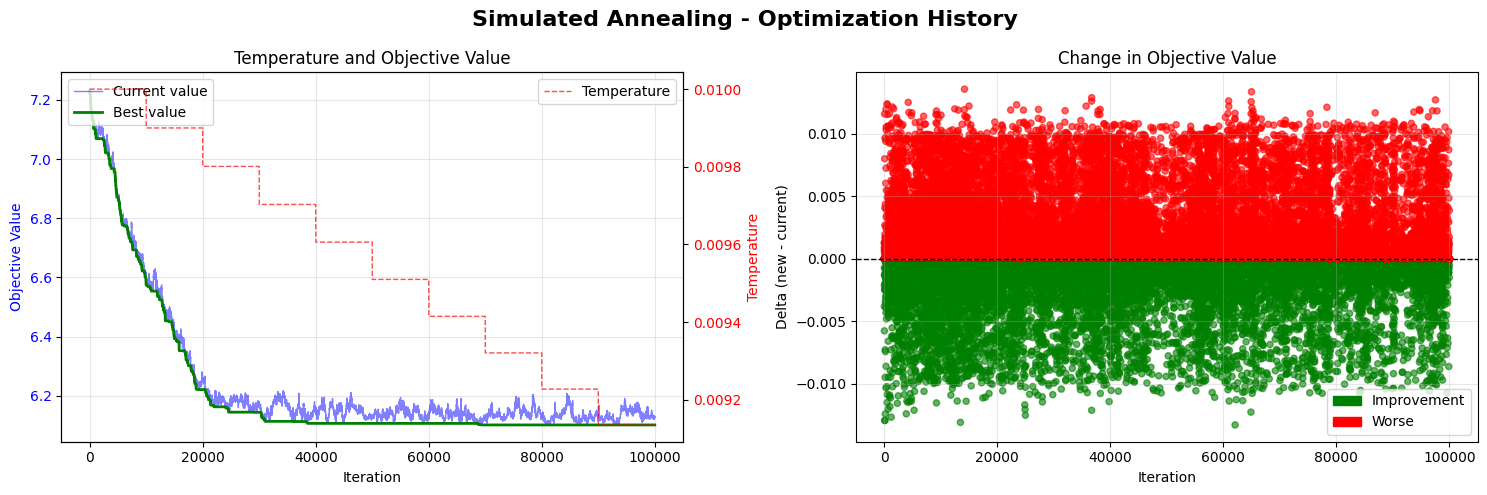

In [13]:
# Visualize optimization history
sa_two_blocks.plot_history(save_path="sa_two_blocks_history.png")



Final best value: 6.100928
Final result plot saved to: sa_two_blocks_result.png


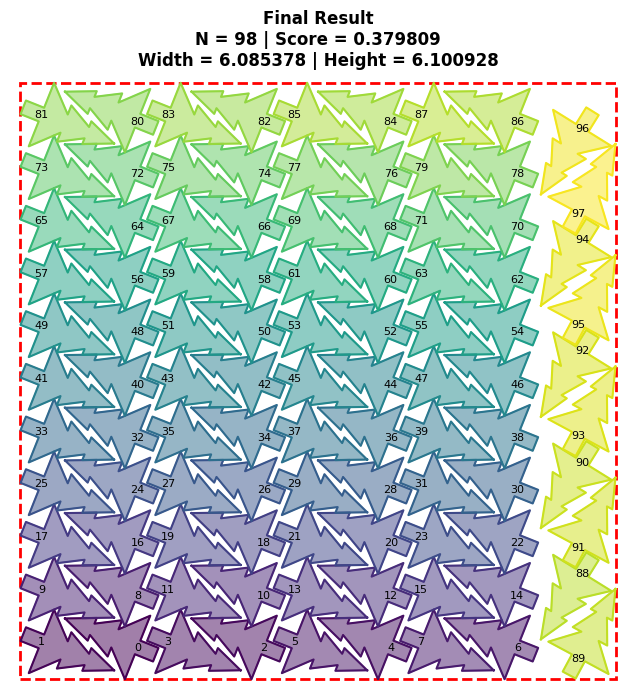

In [14]:
# Visualize result
print(f"\nFinal best value: {float(best_value_2blocks):.6f}")
sa_two_blocks.plot_final_result(best_state_2blocks, save_path="sa_two_blocks_result.png")


In [15]:
# Get the final list of trees from the optimized state
final_trees_2blocks = two_block_problem.translate(best_state_2blocks)

# Save results

In [16]:
import pandas as pd
from decimal import Decimal, getcontext
from shapely import affinity, touches
from shapely.geometry import Polygon
from shapely.ops import unary_union
from shapely.strtree import STRtree

getcontext().prec = 25
scale_factor = Decimal("1e15")

class ChristmasTree:
    """Represents a single, rotatable Christmas tree of a fixed size."""

    def __init__(self, center_x='0', center_y='0', angle='0'):
        """Initializes the Christmas tree with a specific position and rotation."""
        self.center_x = Decimal(center_x)
        self.center_y = Decimal(center_y)
        self.angle = Decimal(angle)

        trunk_w = Decimal('0.15')
        trunk_h = Decimal('0.2')
        base_w = Decimal('0.7')
        mid_w = Decimal('0.4')
        top_w = Decimal('0.25')
        tip_y = Decimal('0.8')
        tier_1_y = Decimal('0.5')
        tier_2_y = Decimal('0.25')
        base_y = Decimal('0.0')
        trunk_bottom_y = -trunk_h

        initial_polygon = Polygon(
            [
                # Start at Tip
                (Decimal('0.0') * scale_factor, tip_y * scale_factor),
                # Right side - Top Tier
                (top_w / Decimal('2') * scale_factor, tier_1_y * scale_factor),
                (top_w / Decimal('4') * scale_factor, tier_1_y * scale_factor),
                # Right side - Middle Tier
                (mid_w / Decimal('2') * scale_factor, tier_2_y * scale_factor),
                (mid_w / Decimal('4') * scale_factor, tier_2_y * scale_factor),
                # Right side - Bottom Tier
                (base_w / Decimal('2') * scale_factor, base_y * scale_factor),
                # Right Trunk
                (trunk_w / Decimal('2') * scale_factor, base_y * scale_factor),
                (trunk_w / Decimal('2') * scale_factor, trunk_bottom_y * scale_factor),
                # Left Trunk
                (-(trunk_w / Decimal('2')) * scale_factor, trunk_bottom_y * scale_factor),
                (-(trunk_w / Decimal('2')) * scale_factor, base_y * scale_factor),
                # Left side - Bottom Tier
                (-(base_w / Decimal('2')) * scale_factor, base_y * scale_factor),
                # Left side - Middle Tier
                (-(mid_w / Decimal('4')) * scale_factor, tier_2_y * scale_factor),
                (-(mid_w / Decimal('2')) * scale_factor, tier_2_y * scale_factor),
                # Left side - Top Tier
                (-(top_w / Decimal('4')) * scale_factor, tier_1_y * scale_factor),
                (-(top_w / Decimal('2')) * scale_factor, tier_1_y * scale_factor),
            ]
        )
        rotated = affinity.rotate(initial_polygon, float(self.angle), origin=(0, 0))
        self.polygon = affinity.translate(rotated,
                                          xoff=float(self.center_x * scale_factor),
                                          yoff=float(self.center_y * scale_factor))
        

    def clone(self) -> "ChristmasTree":
        return ChristmasTree(
            center_x=str(self.center_x),
            center_y=str(self.center_y),
            angle=str(self.angle),
        )    

def get_tree_list_side_lenght(tree_list: list[ChristmasTree]) -> Decimal:
    all_polygons = [t.polygon for t in tree_list]
    bounds = unary_union(all_polygons).bounds
    return Decimal(max(bounds[2] - bounds[0], bounds[3] - bounds[1])) / scale_factor

def get_total_score(dict_of_side_length: dict[str, Decimal]):
    score = 0
    for k, v in dict_of_side_length.items():
        score += v ** 2 / Decimal(k)
    return score

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def plot_layout(ax, placed_trees, title):
    num_trees = len(placed_trees)
    colors = plt.cm.viridis([i / num_trees for i in range(num_trees)])

    all_polygons = [t.polygon for t in placed_trees]
    bounds = unary_union(all_polygons).bounds

    for i, tree in enumerate(placed_trees):
        # Rescale for plotting
        x_scaled, y_scaled = tree.polygon.exterior.xy
        x = [Decimal(val) / scale_factor for val in x_scaled]
        y = [Decimal(val) / scale_factor for val in y_scaled]
        ax.plot(x, y, color=colors[i])
        ax.fill(x, y, alpha=0.5, color=colors[i])

    minx = Decimal(bounds[0]) / scale_factor
    miny = Decimal(bounds[1]) / scale_factor
    maxx = Decimal(bounds[2]) / scale_factor
    maxy = Decimal(bounds[3]) / scale_factor

    width = maxx - minx
    height = maxy - miny
    # side_length = max(width, height)

    side_length = width if width > height else height
    

    square_x = minx if width >= height else minx - (side_length - width) / 2
    square_y = miny if height >= width else miny - (side_length - height) / 2
    bounding_square = Rectangle(
        (float(square_x), float(square_y)),
        float(side_length),
        float(side_length),
        fill=False,
        edgecolor='red',
        linewidth=2,
        linestyle='--',
    )
    ax.add_patch(bounding_square)

    padding = 0.5
    ax.set_xlim(
        float(square_x - Decimal(str(padding))),
        float(square_x + side_length + Decimal(str(padding))))
    ax.set_ylim(float(square_y - Decimal(str(padding))),
                float(square_y + side_length + Decimal(str(padding))))
    ax.set_aspect('equal', adjustable='box')
    ax.axis('off')
    ax.set_title(f'{title}. Side: {side_length:0.8f}')

def plot_difference(layout1, layout2):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
    plot_layout(ax1, layout1, "Orininal")
    plot_layout(ax2, layout2, "After fix")
    plt.tight_layout()
    plt.show()

def parse_csv(csv_path) -> dict[str, list[ChristmasTree]]:
    print(f'parse_csv: {csv_path=}')

    result = pd.read_csv(csv_path)
    result['x'] = result['x'].str.strip('s')
    result['y'] = result['y'].str.strip('s')
    result['deg'] = result['deg'].str.strip('s')
    result[['group_id', 'item_id']] = result['id'].str.split('_', n=2, expand=True)

    dict_of_tree_list = {}
    dict_of_side_length = {}
    for group_id, group_data in result.groupby('group_id'):
        tree_list = [ChristmasTree(center_x=row['x'], center_y=row['y'], angle=row['deg']) for _, row in group_data.iterrows()]
        dict_of_tree_list[group_id] = tree_list
        dict_of_side_length[group_id] = get_tree_list_side_lenght(tree_list)

    return dict_of_tree_list, dict_of_side_length

In [17]:
# Load current best solution
current_solution_path = '/kaggle/input/improuved-1/submission (30).csv'
dict_of_tree_list, dict_of_side_length = parse_csv(current_solution_path)

parse_csv: csv_path='/kaggle/input/improuved-1/submission (30).csv'


In [18]:
dict_of_tree_list['098'] = final_trees_2blocks
dict_of_side_length['098'] = Decimal(best_value_2blocks)

In [19]:
new_score = get_total_score(dict_of_side_length)
print(f'\n{new_score=:0.8f}')


new_score=70.95281005


In [20]:
# Save results
tree_data = []
for group_name, tree_list in dict_of_tree_list.items():
    for item_id, tree in enumerate(tree_list):
        tree_data.append({
            'id': f'{group_name}_{item_id}',
            'x': f's{tree.center_x}',
            'y': f's{tree.center_y}',
            'deg': f's{tree.angle}'
        })
tree_data = pd.DataFrame(tree_data)
tree_data.to_csv('results.csv', index=False) 